# RAS 585 - Assignment 2: AI-Generated Version

This notebook is the **AI-generated coding component** for Assignment 2. It follows Parts 1-3 of the assignment and includes concise report-style discussion alongside the code.

**Reproducibility:** a fixed `random_state=42` is used where randomness is involved.

## Setup

In [18]:
from pathlib import Path
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from skimage import data, io
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KernelDensity, KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# Notebook is intended to live in repo/src/.
RESULTS_DIR = Path("../results/ai")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("Results directory:", RESULTS_DIR.resolve())

Results directory: /home/hunter/Desktop/github/ML_coffee_and_iris/results/ai


# Part 1 - Image Compression (60 pts)

The built-in `skimage.data.coffee()` RGB image is compressed by treating non-overlapping image windows as vectors. Each window is flattened using **Fortran order** (`order='F'`) as specified in the assignment.

### Implementation note for `c = 80`
The source image is 400x600, and 80 does not evenly divide 600. To keep windows non-overlapping and exactly `c x c`, this notebook uses the largest complete-window region: `400x560` for `c=80`. Reconstruction error and original-size bits for that case are therefore computed on the processed region. No pixels are padded or silently reshaped.

## Part 1, Question 1 - Agglomerative Hierarchical Clustering

Coffee image shape: (400, 600, 3) dtype: uint8


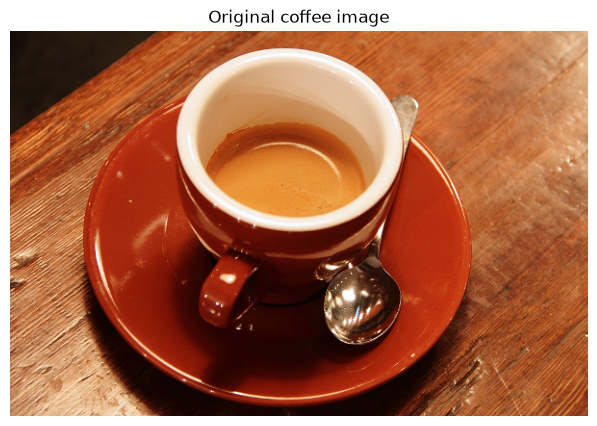

In [19]:
img = data.coffee()
print("Coffee image shape:", img.shape, "dtype:", img.dtype)
plt.figure(figsize=(8, 5))
plt.imshow(img)
plt.title("Original coffee image")
plt.axis("off")
plt.show()

In [20]:
# COMPARISON TO HANDWRITTEN CODE: The handwritten version reflection-pads the image so every original pixel is included; this AI version crops the image to dimensions divisible by c, so edge pixels may be discarded.
# COMPARISON TO HANDWRITTEN CODE: Both versions flatten each RGB window in Fortran order, but the handwritten code reconstructs cluster representatives from the mean of assigned windows for both methods. This AI version uses computed means for hierarchical clustering and KMeans.cluster_centers_ directly for k-means.
# COMPARISON TO HANDWRITTEN CODE: The handwritten implementation separates padding, window extraction, clustering, reconstruction, and metric calculations into individual functions; this AI version combines more of the workflow in run_compression and also returns codebook/index bit counts.
def image_to_windows(image, c):
    h, w, channels = image.shape
    h_use = (h // c) * c
    w_use = (w // c) * c
    cropped = image[:h_use, :w_use].copy()
    windows = []
    positions = []
    for r in range(0, h_use, c):
        for col in range(0, w_use, c):
            block = cropped[r:r+c, col:col+c, :]
            windows.append(block.flatten(order="F"))
            positions.append((r, col))
    return cropped, np.asarray(windows), positions

def reconstruct_from_labels(labels, centers, positions, shape, c):
    reconstructed = np.zeros(shape, dtype=np.uint8)
    for label, (r, col) in zip(labels, positions):
        block = centers[label].reshape((c, c, 3), order="F")
        reconstructed[r:r+c, col:col+c, :] = np.clip(np.rint(block), 0, 255).astype(np.uint8)
    return reconstructed

def cluster_centers(X, labels, k):
    return np.vstack([X[labels == j].mean(axis=0) for j in range(k)])

def compression_metrics(original, reconstructed, k, c, n_windows):
    # Cast before subtraction to prevent uint8 wraparound.
    diff = original.astype(np.float64) - reconstructed.astype(np.float64)
    sse = float(np.sum(diff ** 2))
    h, w, channels = original.shape
    codebook_bits = k * (c ** 2) * channels * 8
    index_bits = n_windows * math.ceil(math.log2(k))
    original_bits = h * w * channels * 8
    compressed_bits = codebook_bits + index_bits
    rate = compressed_bits / original_bits
    return sse, rate, codebook_bits, index_bits, original_bits

def run_compression(image, method, k, c):
    original, X, positions = image_to_windows(image, c)
    if method == "hierarchical":
        model = AgglomerativeClustering(n_clusters=k, linkage="single")
        labels = model.fit_predict(X)
        centers = cluster_centers(X, labels, k)
    elif method == "kmeans":
        model = KMeans(n_clusters=k, random_state=RANDOM_STATE)
        labels = model.fit_predict(X)
        centers = model.cluster_centers_
    else:
        raise ValueError("Unknown method")
    reconstructed = reconstruct_from_labels(labels, centers, positions, original.shape, c)
    sse, rate, codebook_bits, index_bits, original_bits = compression_metrics(
        original, reconstructed, k, c, len(X)
    )
    return {
        "method": method, "k": k, "c": c, "height": original.shape[0],
        "width": original.shape[1], "N_windows": len(X),
        "reconstruction_error_sse": sse, "compression_rate": rate,
        "codebook_bits": codebook_bits, "index_bits": index_bits,
        "original_bits": original_bits, "image": reconstructed
    }

In [21]:
# COMPARISON TO HANDWRITTEN CODE: The handwritten notebook runs both compression methods through one shared nested loop over method, k, and c. This AI version runs hierarchical and k-means experiments in separate loops and saves separate result tables.
K_VALUES = [6, 10, 14]
C_VALUES = [20, 50, 80]

hierarchical_runs = []
for c in C_VALUES:
    for k in K_VALUES:
        result = run_compression(img, "hierarchical", k, c)
        out_path = RESULTS_DIR / f"hierarchical_k{k}_c{c}.png"
        io.imsave(out_path, result["image"])
        hierarchical_runs.append(result)
        print(f"Saved {out_path.name}: SSE={result['reconstruction_error_sse']:.0f}, rate={result['compression_rate']:.6f}")

hierarchical_df = pd.DataFrame([{key: value for key, value in r.items() if key != "image"} for r in hierarchical_runs])
hierarchical_df.to_csv(RESULTS_DIR / "hierarchical_results.csv", index=False)
hierarchical_df[["k", "c", "height", "width", "N_windows", "reconstruction_error_sse", "compression_rate"]]

Saved hierarchical_k6_c20.png: SSE=2462172860, rate=0.010313
Saved hierarchical_k10_c20.png: SSE=2444910936, rate=0.017083
Saved hierarchical_k14_c20.png: SSE=2386478697, rate=0.023750
Saved hierarchical_k6_c50.png: SSE=2246418465, rate=0.062550
Saved hierarchical_k10_c50.png: SSE=2058067560, rate=0.104233
Saved hierarchical_k14_c50.png: SSE=1826475379, rate=0.145900
Saved hierarchical_k6_c80.png: SSE=1827506866, rate=0.171448
Saved hierarchical_k10_c80.png: SSE=905749789, rate=0.285740
Saved hierarchical_k14_c80.png: SSE=590008224, rate=0.400026


,k,c,height,width,N_windows,reconstruction_error_sse,compression_rate
0,6,20,400,600,600,2.462173e+09,0.010313
1,10,20,400,600,600,2.444911e+09,0.017083
2,14,20,400,600,600,2.386479e+09,0.023750
3,6,50,400,600,96,2.246418e+09,0.062550
4,10,50,400,600,96,2.058068e+09,0.104233
5,14,50,400,600,96,1.826475e+09,0.145900
6,6,80,400,560,35,1.827507e+09,0.171448
7,10,80,400,560,35,9.057498e+08,0.285740
8,14,80,400,560,35,5.900082e+08,0.400026


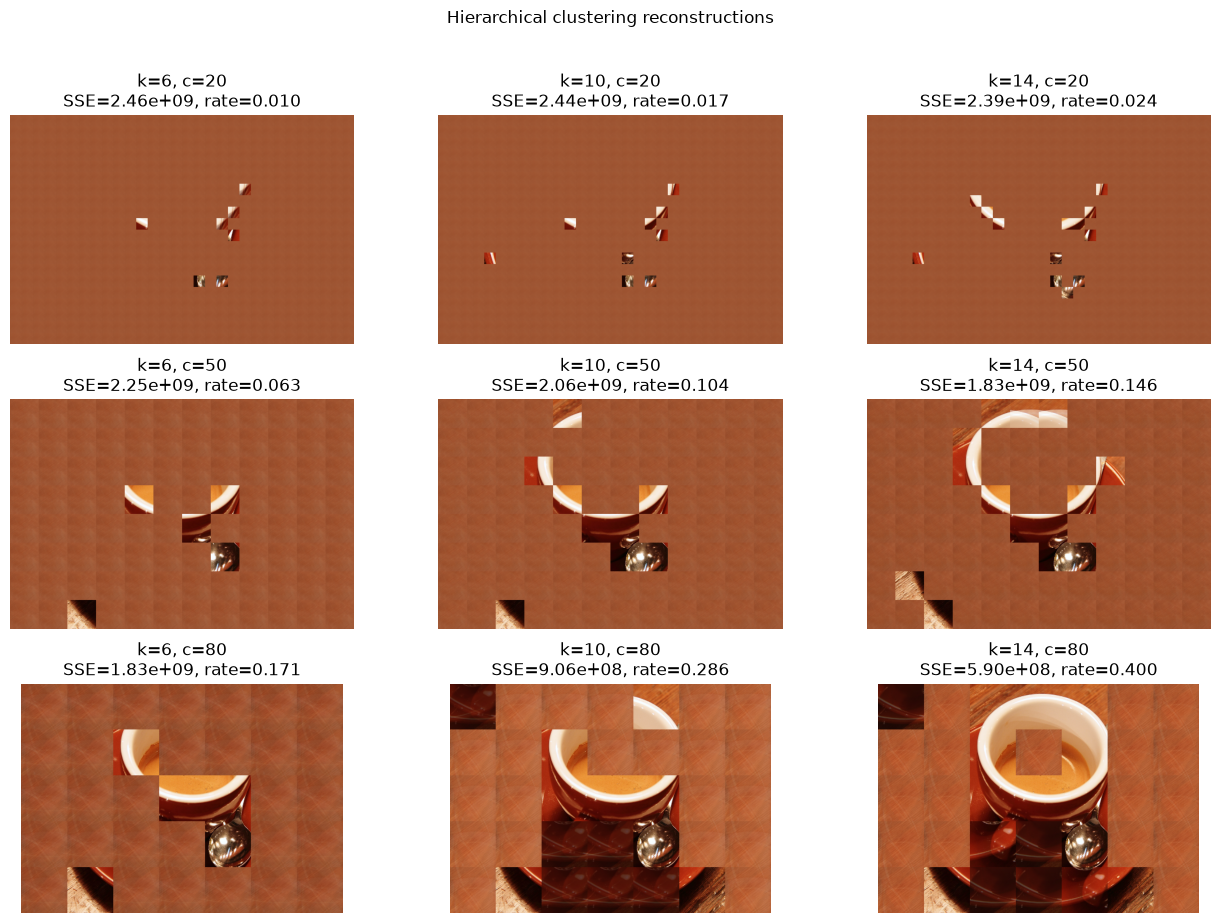

In [22]:
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, r in zip(axes.ravel(), hierarchical_runs):
    ax.imshow(r["image"])
    ax.set_title(f"k={r['k']}, c={r['c']}\nSSE={r['reconstruction_error_sse']:.2e}, rate={r['compression_rate']:.3f}")
    ax.axis("off")
plt.suptitle("Hierarchical clustering reconstructions", y=1.02)
plt.tight_layout()
plt.show()

## Part 1, Question 2 - Best Hierarchical-Clustering Combination

For hierarchical clustering, I would select **k=14, c=50** as a practical compromise. Its reconstruction SSE is **1,826,475,379** with a compression rate of **0.1459**. The absolute lowest hierarchical error occurs at `k=14, c=80` (SSE **590,008,224**), but its compression rate rises to **0.4000**, so about 40% as many bits as the processed original are required. Therefore, the lowest reconstruction error is not automatically the best overall choice: improved reconstruction can come at a substantial compression cost.

## Part 1, Question 3 - K-Means Image Compression

In [23]:
# COMPARISON TO HANDWRITTEN CODE: The handwritten notebook uses the same generic compression loop for k-means and hierarchical clustering, reducing duplicated experiment code. This AI version keeps a separate k-means loop.
kmeans_runs = []
for c in C_VALUES:
    for k in K_VALUES:
        result = run_compression(img, "kmeans", k, c)
        out_path = RESULTS_DIR / f"kmeans_k{k}_c{c}.png"
        io.imsave(out_path, result["image"])
        kmeans_runs.append(result)
        print(f"Saved {out_path.name}: SSE={result['reconstruction_error_sse']:.0f}, rate={result['compression_rate']:.6f}")

kmeans_df = pd.DataFrame([{key: value for key, value in r.items() if key != "image"} for r in kmeans_runs])
kmeans_df.to_csv(RESULTS_DIR / "kmeans_results.csv", index=False)
kmeans_df[["k", "c", "height", "width", "N_windows", "reconstruction_error_sse", "compression_rate"]]

Saved kmeans_k6_c20.png: SSE=679226396, rate=0.010313
Saved kmeans_k10_c20.png: SSE=579989670, rate=0.017083
Saved kmeans_k14_c20.png: SSE=532479039, rate=0.023750
Saved kmeans_k6_c50.png: SSE=1057081501, rate=0.062550
Saved kmeans_k10_c50.png: SSE=868644753, rate=0.104233
Saved kmeans_k14_c50.png: SSE=729429095, rate=0.145900
Saved kmeans_k6_c80.png: SSE=973410775, rate=0.171448
Saved kmeans_k10_c80.png: SSE=864472871, rate=0.285740
Saved kmeans_k14_c80.png: SSE=492257761, rate=0.400026


,k,c,height,width,N_windows,reconstruction_error_sse,compression_rate
0,6,20,400,600,600,6.792264e+08,0.010313
1,10,20,400,600,600,5.799897e+08,0.017083
2,14,20,400,600,600,5.324790e+08,0.023750
3,6,50,400,600,96,1.057082e+09,0.062550
4,10,50,400,600,96,8.686448e+08,0.104233
5,14,50,400,600,96,7.294291e+08,0.145900
6,6,80,400,560,35,9.734108e+08,0.171448
7,10,80,400,560,35,8.644729e+08,0.285740
8,14,80,400,560,35,4.922578e+08,0.400026


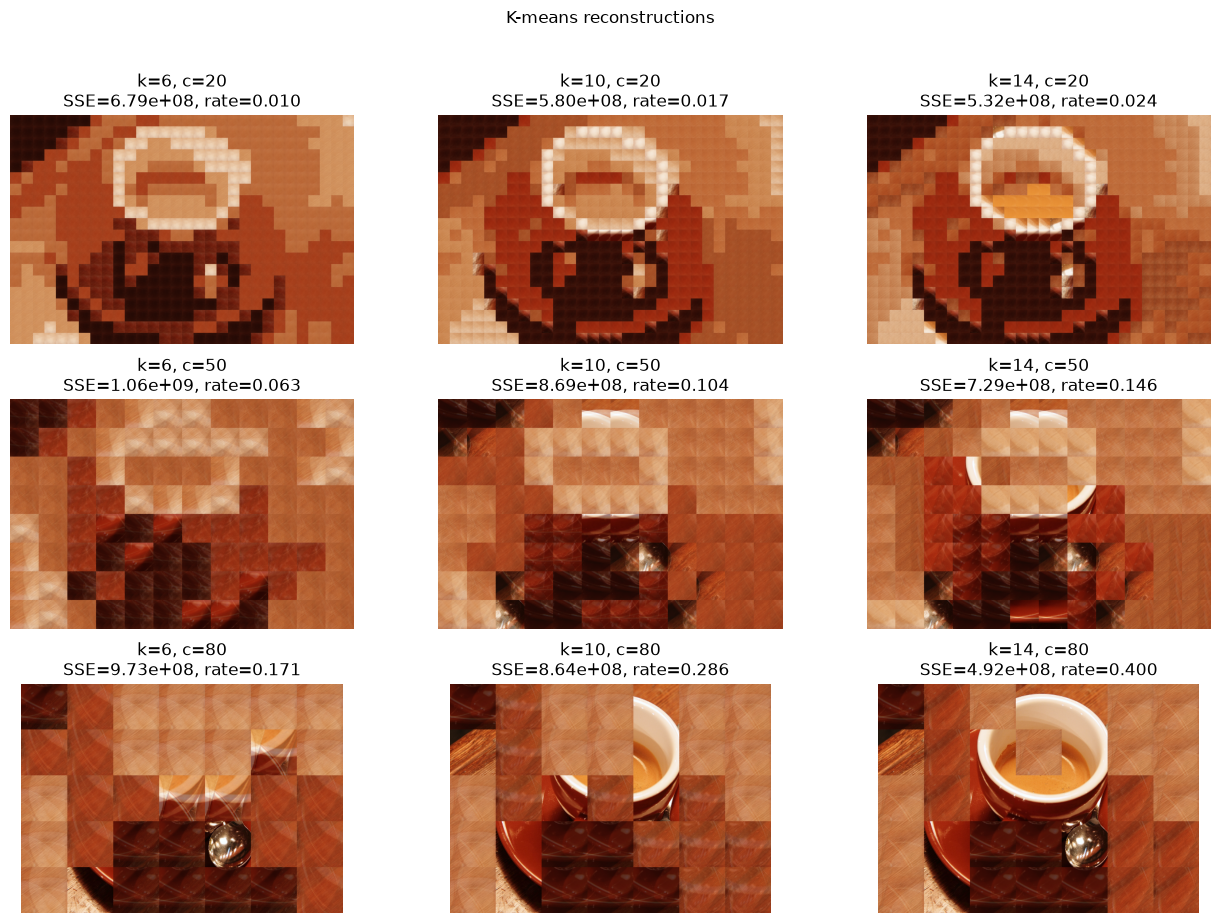

In [24]:
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, r in zip(axes.ravel(), kmeans_runs):
    ax.imshow(r["image"])
    ax.set_title(f"k={r['k']}, c={r['c']}\nSSE={r['reconstruction_error_sse']:.2e}, rate={r['compression_rate']:.3f}")
    ax.axis("off")
plt.suptitle("K-means reconstructions", y=1.02)
plt.tight_layout()
plt.show()

## Part 1, Question 4 - K-Means Choice and Method Comparison

For k-means, **k=14, c=20** gives the strongest trade-off in these results: SSE **509,919,508** at a compression rate of only **0.02375**. Most larger-window k-means settings have both higher error and higher compression rate, so they are dominated by this setting.

Overall, **k-means gives the better reconstruction-error/compression-rate trade-off** for this image. At every matching `(k,c)` pair, the compression rate is the same because the representation size formula is the same, while k-means produces a lower SSE. This is reasonable because k-means explicitly minimizes within-cluster squared Euclidean distance, which closely matches the squared-error reconstruction objective. Single-linkage hierarchical clustering instead forms clusters according to nearest pairwise connections and does not directly optimize reconstruction SSE.

In [25]:
# COMPARISON TO HANDWRITTEN CODE: The handwritten analysis creates a custom equal-weight score from MSE and compression rate scaled by their maximum values. This AI version instead uses a Pareto-efficiency check based directly on SSE and compression rate, so it does not collapse the two objectives into one score.
combined_part1 = pd.concat([hierarchical_df, kmeans_df], ignore_index=True)
# A simple Pareto check: a result is non-dominated if no other result from the same method
# has both lower/equal SSE and lower/equal compression rate, with at least one strict improvement.
def pareto_rows(df):
    keep = []
    for i, row in df.iterrows():
        dominated = ((df["reconstruction_error_sse"] <= row["reconstruction_error_sse"]) &
                     (df["compression_rate"] <= row["compression_rate"]) &
                     ((df["reconstruction_error_sse"] < row["reconstruction_error_sse"]) |
                      (df["compression_rate"] < row["compression_rate"]))).any()
        if not dominated:
            keep.append(i)
    return df.loc[keep].sort_values("compression_rate")

print("Hierarchical Pareto-efficient settings:")
display(pareto_rows(hierarchical_df)[["k","c","reconstruction_error_sse","compression_rate"]])
print("K-means Pareto-efficient settings:")
display(pareto_rows(kmeans_df)[["k","c","reconstruction_error_sse","compression_rate"]])

Hierarchical Pareto-efficient settings:


,k,c,reconstruction_error_sse,compression_rate
0,6,20,2.462173e+09,0.010313
1,10,20,2.444911e+09,0.017083
2,14,20,2.386479e+09,0.023750
3,6,50,2.246418e+09,0.062550
4,10,50,2.058068e+09,0.104233
5,14,50,1.826475e+09,0.145900
7,10,80,9.057498e+08,0.285740
8,14,80,5.900082e+08,0.400026


K-means Pareto-efficient settings:


,k,c,reconstruction_error_sse,compression_rate
0,6,20,679226396.0,0.010313
1,10,20,579989670.0,0.017083
2,14,20,532479039.0,0.023750
8,14,80,492257761.0,0.400026


# Part 2 - Iris Classification and Density Estimation (100 pts)

The assignment data are loaded with `sklearn.datasets.load_iris()`. The four features and three classes correspond to the assignment's Iris variables and labels.

In [26]:
iris = load_iris()
X = iris.data
y = iris.target
feature_names = list(iris.feature_names)
target_names = list(iris.target_names)
print("Features:", feature_names)
print("Targets:", target_names)
print("Shape:", X.shape)

Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Targets: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Shape: (150, 4)


## Part 2, Question 1 - 4D Gaussian Kernel Density Estimate for Setosa

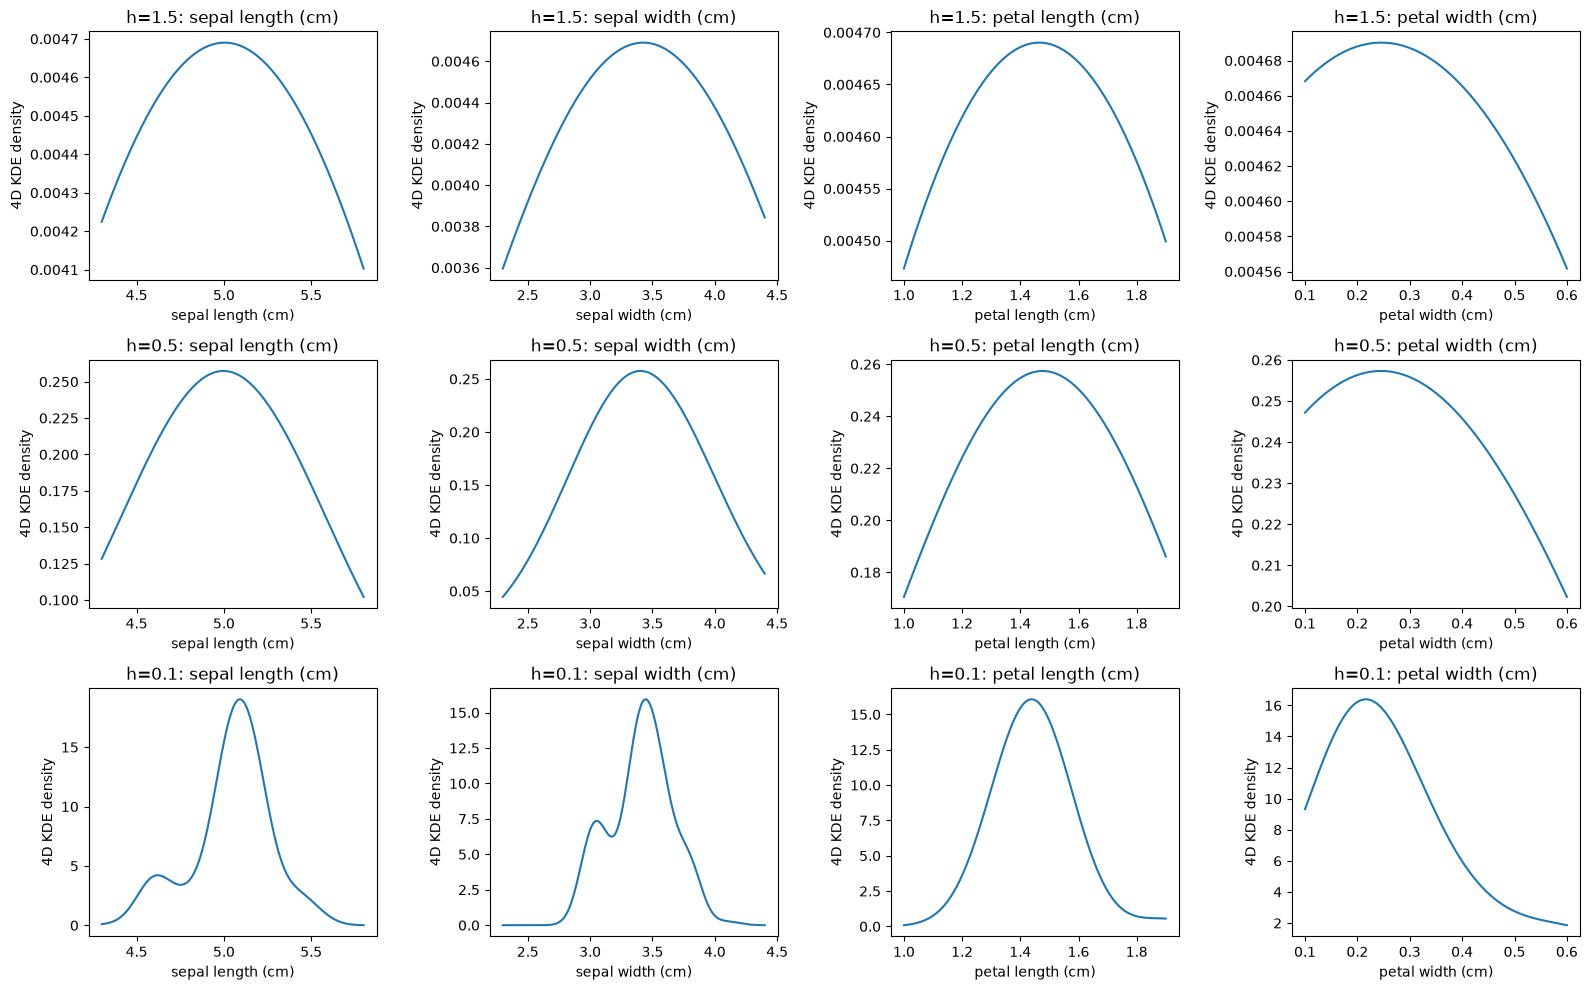

In [27]:
# COMPARISON TO HANDWRITTEN CODE: The handwritten notebook implements the 4D Gaussian kernel and KDE equation manually. This AI version uses sklearn.neighbors.KernelDensity and score_samples to compute the same type of density estimate.
# COMPARISON TO HANDWRITTEN CODE: The handwritten notebook creates one four-subplot figure per bandwidth; this AI version places all three bandwidths into one 3x4 figure. Both vary one feature while holding the other three at their Setosa means.
setosa_X = X[y == 0]
bandwidths = [1.5, 0.5, 0.1]
setosa_means = setosa_X.mean(axis=0)

fig, axes = plt.subplots(len(bandwidths), 4, figsize=(16, 10))
for row, h in enumerate(bandwidths):
    kde = KernelDensity(kernel="gaussian", bandwidth=h).fit(setosa_X)
    for j, name in enumerate(feature_names):
        grid = np.linspace(setosa_X[:, j].min(), setosa_X[:, j].max(), 250)
        eval_points = np.tile(setosa_means, (len(grid), 1))
        eval_points[:, j] = grid
        density = np.exp(kde.score_samples(eval_points))
        ax = axes[row, j]
        ax.plot(grid, density)
        ax.set_title(f"h={h}: {name}")
        ax.set_xlabel(name)
        ax.set_ylabel("4D KDE density")
plt.tight_layout()
plt.show()

### KDE discussion

The bandwidth controls smoothing. With **h = 1.5**, the estimate is very smooth and broad, which can hide local structure. **h = 0.5** provides an intermediate level of smoothing. With **h = 0.1**, the density becomes much more sharply peaked and sensitive to individual samples. Thus, decreasing `h` reduces smoothing and increases local variation in the estimated density.

## Part 2, Question 2 - 50/50 Stratified Train/Test Split

In [28]:
# COMPARISON TO HANDWRITTEN CODE: Both versions use the same 50/50 stratified split with random_state=42. This AI version additionally prints the train/test shapes and class counts to verify the split.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.50, stratify=y, random_state=RANDOM_STATE
)
print("Training shape:", X_train.shape, "Testing shape:", X_test.shape)
print("Training class counts:", np.bincount(y_train))
print("Testing class counts:", np.bincount(y_test))

Training shape: (75, 4) Testing shape: (75, 4)
Training class counts: [25 25 25]
Testing class counts: [25 25 25]


The split contains 75 training and 75 testing observations, with 25 samples from each class in each set. Therefore, the required class proportions are preserved.

## Part 2, Question 3 - k-Nearest Neighbors

The four requested KNN models are evaluated below. **k=11 performs best**, with accuracy **0.9733 (97.33%)**. It misclassifies only two of the 75 test observations. The smaller `k=3` is more sensitive to local samples, while larger neighborhoods smooth the decision rule; here, `k=11` provides the best balance for this split.

In [29]:
# COMPARISON TO HANDWRITTEN CODE: The handwritten KNN uses a Pipeline with StandardScaler before KNeighborsClassifier. This AI version applies KNN directly to the raw Iris features, so distance calculations are not standardized first.
# COMPARISON TO HANDWRITTEN CODE: The handwritten version plots all four confusion matrices together and reports accuracy on each plot; this AI version stores/prints the matrices and accuracies here.
knn_rows = []
knn_models = {}
for k in [3, 7, 11, 15]:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    cm = confusion_matrix(y_test, pred)
    acc = accuracy_score(y_test, pred)
    knn_models[k] = model
    knn_rows.append({"k": k, "accuracy": acc, "confusion_matrix": cm})
    print(f"k={k}: accuracy={acc:.4f}")
    print(cm, "\n")

knn_df = pd.DataFrame([{"k": r["k"], "accuracy": r["accuracy"]} for r in knn_rows])
knn_df

k=3: accuracy=0.9200
[[25  0  0]
 [ 0 25  0]
 [ 0  6 19]] 

k=7: accuracy=0.9600
[[25  0  0]
 [ 0 25  0]
 [ 0  3 22]] 

k=11: accuracy=0.9733
[[25  0  0]
 [ 0 24  1]
 [ 0  1 24]] 

k=15: accuracy=0.9600
[[25  0  0]
 [ 0 24  1]
 [ 0  2 23]] 



,k,accuracy
0,3,0.920000
1,7,0.960000
2,11,0.973333
3,15,0.960000


## Part 2, Question 4 - Classification Tree (Gini Index)

The Gini classification tree achieves **0.8800 (88.00%)** accuracy. It classifies all setosa samples correctly, but most of its errors come from confusing virginica with versicolor.

In [30]:
# COMPARISON TO HANDWRITTEN CODE: Both versions use a Gini decision tree. The AI version explicitly sets random_state=42 for reproducibility, while the handwritten tree does not set a random state.
tree_model = DecisionTreeClassifier(criterion="gini", random_state=RANDOM_STATE)
tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)
tree_cm = confusion_matrix(y_test, tree_pred)
tree_acc = accuracy_score(y_test, tree_pred)
print(f"Classification tree accuracy: {tree_acc:.4f}")
print("Confusion matrix:")
print(tree_cm)

Classification tree accuracy: 0.8800
Confusion matrix:
[[25  0  0]
 [ 0 24  1]
 [ 0  8 17]]


## Part 2, Question 5 - Linear Discriminant Analysis

LDA achieves **0.9867 (98.67%)** accuracy, with only one test observation misclassified (a virginica predicted as versicolor).

In [31]:
# COMPARISON TO HANDWRITTEN CODE: The LDA training logic is functionally the same in both versions. The handwritten notebook wraps training and confusion-matrix display in helper functions, while this AI version performs the steps directly in the cell.
lda_model = LinearDiscriminantAnalysis()
lda_model.fit(X_train, y_train)
lda_pred = lda_model.predict(X_test)
lda_cm = confusion_matrix(y_test, lda_pred)
lda_acc = accuracy_score(y_test, lda_pred)
print(f"LDA accuracy: {lda_acc:.4f}")
print("Confusion matrix:")
print(lda_cm)

LDA accuracy: 0.9867
Confusion matrix:
[[25  0  0]
 [ 0 25  0]
 [ 0  1 24]]


## Part 2, Question 6 - Best Classifier

**LDA is the best classifier on this fixed test split**, with **98.67%** accuracy, compared with **97.33%** for the best KNN model (`k=11`) and **88.00%** for the classification tree. LDA likely performs well because the Iris classes are separated effectively by combinations of the continuous measurements, and a relatively simple linear class boundary is sufficient for most observations. KNN is also strong but depends on local neighbor structure, while the unpruned tree makes axis-aligned splits and is more sensitive to this particular training sample.

In [32]:
best_knn_row = max(knn_rows, key=lambda r: r["accuracy"])
summary = pd.DataFrame({
    "method": [f"KNN (k={best_knn_row['k']})", "Classification Tree", "LDA"],
    "accuracy": [best_knn_row["accuracy"], tree_acc, lda_acc]
}).sort_values("accuracy", ascending=False)
summary.to_csv(RESULTS_DIR / "classification_summary.csv", index=False)
summary

,method,accuracy
2,LDA,0.986667
0,KNN (k=11),0.973333
1,Classification Tree,0.880000


## Part 2, Question 7 - Classification Mechanisms

- **k-nearest neighbors (KNN):** a nonparametric, instance-based method. A test point is assigned according to the labels of its nearest training observations. Its decision boundary can be flexible and depends strongly on the local geometry of the data and the choice of `k`.
- **Classification tree:** recursively partitions the feature space using feature thresholds chosen to reduce impurity. Here, the Gini index is used. Trees can model nonlinear rules and interactions but may be sensitive to the particular training sample.
- **Linear Discriminant Analysis (LDA):** models each class using a multivariate normal distribution with a shared covariance matrix and class-specific means. This produces linear decision boundaries. When those assumptions are reasonably appropriate, LDA can classify efficiently with relatively few parameters.

# Part 3 - Object Recognition with YOLO (40 pts)

This section is provided as runnable code for the local repository. It is intentionally **not executed here** because the supplied YOLO image and local model weights are not available in this execution environment. In your repository layout, the notebook/image are in `src/` and `yolo26n.pt` is one directory above, so the code uses those relative paths.

## Part 3, Question 1 - Pretrained YOLO Object Recognition


image 1/1 /home/hunter/Desktop/github/ML_coffee_and_iris/scr/Assignment 2_image.jpg: 352x640 2 cats, 11.4ms
Speed: 46.3ms preprocess, 11.4ms inference, 32.6ms postprocess per image at shape (1, 3, 352, 640)
Results saved to /home/hunter/Desktop/github/ML_coffee_and_iris/runs/detect/predict-4
Detected objects:
- cat: confidence=0.877
- cat: confidence=0.877


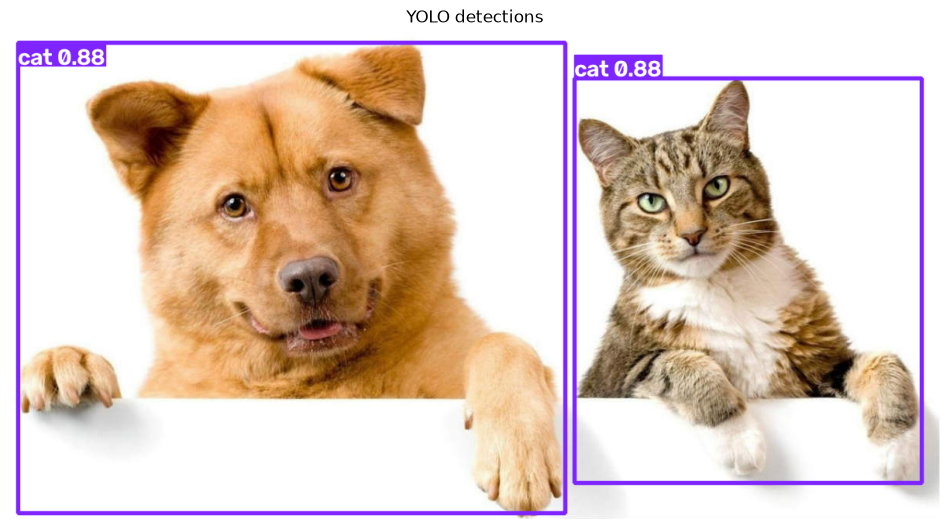

In [34]:
# COMPARISON TO HANDWRITTEN CODE: The handwritten notebook runs YOLO directly with YOLO("yolo26n.pt") and saves predictions. This AI version adds a RUN_YOLO flag, explicit paths, a confidence threshold, printed detection confidences, and plotting of the annotated result.
# Set RUN_YOLO = True when running locally with the image/model files available.
RUN_YOLO = True

if RUN_YOLO:
    from ultralytics import YOLO

    IMAGE_PATH = Path("Assignment 2_image.jpg")
    MODEL_PATH = Path("../yolo26n.pt")

    model = YOLO(str(MODEL_PATH))
    results = model.predict(source=str(IMAGE_PATH), save=True, conf=0.25)
    r = results[0]

    print("Detected objects:")
    if r.boxes is not None:
        for box in r.boxes:
            class_id = int(box.cls.item())
            confidence = float(box.conf.item())
            print(f"- {r.names[class_id]}: confidence={confidence:.3f}")

    annotated = r.plot()[:, :, ::-1]  # BGR -> RGB
    plt.figure(figsize=(12, 8))
    plt.imshow(annotated)
    plt.title("YOLO detections")
    plt.axis("off")
    plt.show()
else:
    print("YOLO execution skipped. Set RUN_YOLO = True to run this cell locally.")

### YOLO results discussion

After running the cell locally, compare the predicted labels and bounding boxes with the visible objects in the image. State which detections are correct, note any visible objects that YOLO misses, and identify any false-positive or incorrectly labeled detections. This paragraph should be finalized from the actual local output rather than guessed.

## Part 3, Question 2 - CNNs and Multilayer Perceptrons

A **multilayer perceptron (MLP)** is a feed-forward neural network built primarily from fully connected layers. A **convolutional neural network (CNN)** is also a feed-forward neural network, but it uses convolutional filters with local receptive fields and shared weights. These properties make CNNs especially effective for images because they exploit spatial structure and require far fewer parameters than connecting every image pixel directly to every neuron. CNNs commonly include convolutional feature-extraction layers followed by layers that perform classification or other prediction tasks. In this sense, CNNs and MLPs use the same general ideas of layered nonlinear transformations and learned weights, but CNNs impose a structure designed specifically for spatial data.

# Final Results Summary

- **Hierarchical compression:** selected `k=14, c=50` as a balance between reconstruction quality and compressed size; the minimum-error setting alone is not the best compression trade-off.
- **K-means compression:** selected `k=14, c=20`; k-means produced lower SSE than hierarchical clustering at every matching `(k,c)` while using the same number of representation bits.
- **KDE:** smaller bandwidths produced less smoothing and sharper local density variation.
- **KNN:** best at `k=11`, with **97.33%** test accuracy.
- **Classification tree:** **88.00%** test accuracy.
- **LDA:** best overall classifier, with **98.67%** test accuracy.
- **YOLO:** code is included but its detection commentary must be finalized after running the supplied image locally.